<a href="https://colab.research.google.com/github/prisha230405/customer-churn-prediction/blob/main/customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv


{'WA_Fn-UseC_-Telco-Customer-Churn (1).csv': b'customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn\r\n7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No\r\n5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No\r\n3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes\r\n7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No\r\n9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes\r\n9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)          # (7043, 21)
print(df.head())         # first 5 customers
print(df.info())         # column types
print(df["Churn"].value_counts())


(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [19]:
# Reload the original file (this gives back the untouched data)
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Clean (run this cell only ONCE)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna()
df = df.drop("customerID", axis=1)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print(df.shape)   # should print (7032, 20)

(7032, 20)


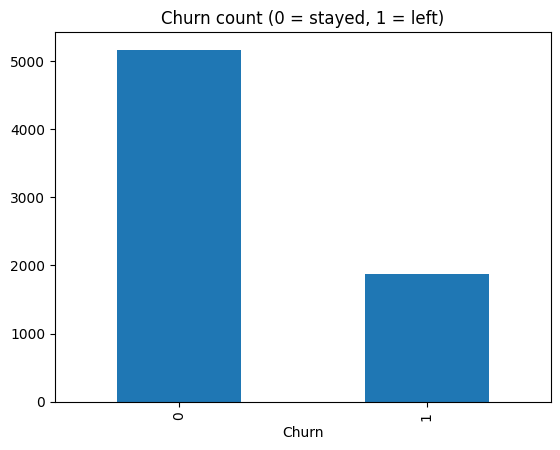

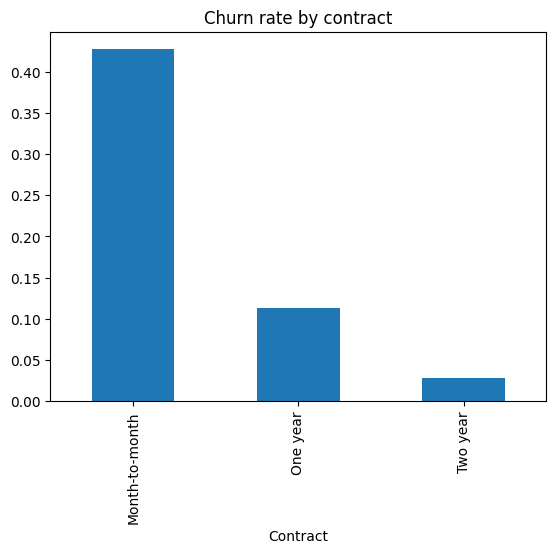

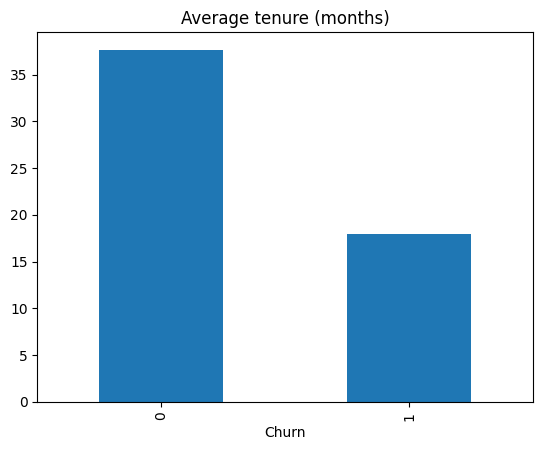

In [20]:
# Chart 1: churn count
df["Churn"].value_counts().plot(kind="bar")
plt.title("Churn count (0 = stayed, 1 = left)")
plt.show()

# Chart 2: churn rate by contract type
df.groupby("Contract")["Churn"].mean().plot(kind="bar")
plt.title("Churn rate by contract")
plt.show()

# Chart 3: tenure of leavers vs stayers
df.groupby("Churn")["tenure"].mean().plot(kind="bar")
plt.title("Average tenure (months)")
plt.show()

In [21]:
X = pd.get_dummies(df.drop("Churn", axis=1), drop_first=True)
y = df["Churn"]

print(X.shape)   # around (7032, 30)

(7032, 30)


In [22]:
X = pd.get_dummies(df.drop("Churn", axis=1), drop_first=True)
y = df["Churn"]

print(X.shape)   # around (7032, 30)

(7032, 30)


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn from training only
X_test_s = scaler.transform(X_test)

print(len(X_train), len(X_test))   # 5625 1407

5625 1407


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_s, y_train)          # study
    pred = model.predict(X_test_s)         # take the exam
    predictions[name] = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results_table = pd.DataFrame(results)
print(results_table.round(3))

                 Model  Accuracy  Precision  Recall     F1
0  Logistic Regression     0.804      0.648   0.575  0.609
1        Decision Tree     0.778      0.581   0.596  0.588
2        Random Forest     0.788      0.623   0.513  0.563


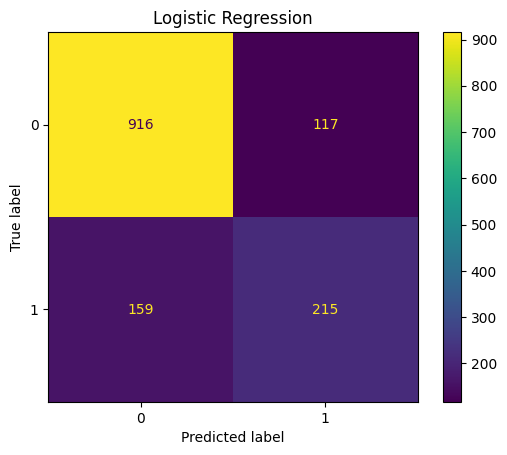

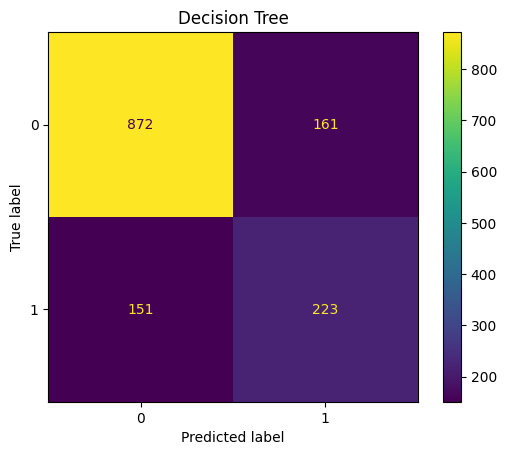

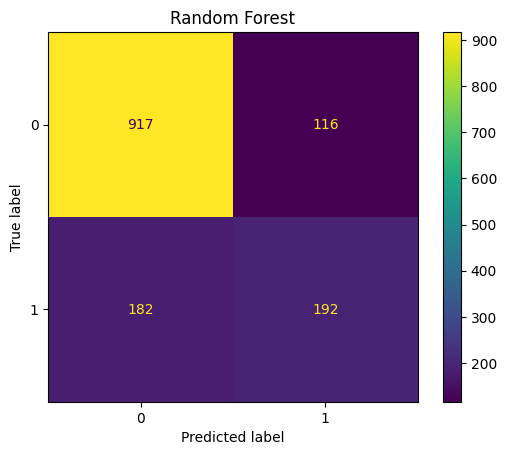

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, pred in predictions.items():
    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title(name)
    plt.show()

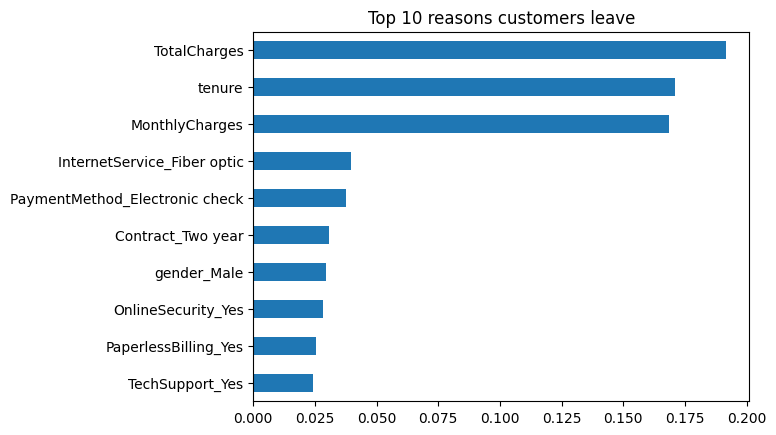

In [26]:
rf = models["Random Forest"]

importance = pd.Series(rf.feature_importances_, index=X.columns)
importance.sort_values(ascending=False).head(10).plot(kind="barh")
plt.title("Top 10 reasons customers leave")
plt.gca().invert_yaxis()
plt.show()

In [29]:
better_rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
better_rf.fit(X_train_s, y_train)
pred = better_rf.predict(X_test_s)



In [30]:
print("===== BALANCED RANDOM FOREST =====")
print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall   :", round(recall_score(y_test, pred), 3))
print("F1       :", round(f1_score(y_test, pred), 3))

results_table.round(3).to_csv("results.csv", index=False)
print("Saved results.csv")

===== BALANCED RANDOM FOREST =====
Accuracy : 0.787
Precision: 0.627
Recall   : 0.489
F1       : 0.55
Saved results.csv
